# COMP3220 Assignment: Heart Failure Prediction
**Students:** *620139183 & 620154625*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42

### --> Load the data

In [2]:
df = pd.read_csv("heart_train.csv")
test_df = pd.read_csv("heart_test.csv")
print(df.shape, test_df.shape)
df.head()

(818, 13) (100, 12)


,PatientId,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,0,34,M,ATA,150,214,0,ST,168,N,0.0,Up,0
1,1,59,M,ASY,178,0,1,LVH,120,Y,0.0,Flat,1
2,2,58,M,ASY,115,0,1,Normal,138,N,0.5,Up,1
3,3,60,M,ASY,130,253,0,Normal,144,Y,1.4,Up,1
4,4,52,M,ASY,165,0,1,Normal,122,Y,1.0,Up,1


### --> Clean and explore the data

In [3]:
print(df.isnull().sum(), "\n")
print("Duplicate rows (ignoring PatientId):",
      df.drop(columns=["PatientId"], errors="ignore").duplicated().sum())
print("RestingBP == 0:", (df["RestingBP"] == 0).sum())
print("Cholesterol == 0:", (df["Cholesterol"] == 0).sum())
print("\nClass balance:\n", df["HeartDisease"].value_counts(normalize=True))

df.describe()

PatientId         0
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64 

Duplicate rows (ignoring PatientId): 0
RestingBP == 0: 1
Cholesterol == 0: 151

Class balance:
 HeartDisease
1    0.545232
0    0.454768
Name: proportion, dtype: float64


,PatientId,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,818.000000,818.000000,818.000000,818.000000,818.000000,818.000000,818.000000,818.000000
mean,408.500000,53.512225,132.506112,197.960880,0.229829,137.122249,0.878851,0.545232
std,236.280554,9.494595,18.690105,108.132239,0.420980,25.609098,1.068329,0.498254
min,0.000000,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,204.250000,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,408.500000,54.000000,130.000000,221.000000,0.000000,138.000000,0.500000,1.000000
75%,612.750000,60.000000,140.000000,265.750000,0.000000,156.000000,1.500000,1.000000
max,817.000000,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [4]:
df = df.drop_duplicates(subset=[c for c in df.columns if c != "PatientId"]).reset_index(drop=True) # duplicates are dropped

# a RestingBP or Cholesterol of 0 is physiologically impossible, so it is treated as missing (NaN) and imputed with the median 
# because there are too many 0-value data
for col in ["RestingBP", "Cholesterol"]:
    df[col] = df[col].replace(0, np.nan)
    test_df[col] = test_df[col].replace(0, np.nan)

print(df[["RestingBP", "Cholesterol"]].isnull().sum())

RestingBP        1
Cholesterol    151
dtype: int64


### --> Features and Labels

In [5]:
y = df["HeartDisease"]
X = df.drop(columns=["HeartDisease", "PatientId"], errors="ignore")

numeric_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
categorical_cols = ["Sex", "ChestPainType", "FastingBS", "RestingECG", "ExerciseAngina", "ST_Slope"]

# FastingBS is already 0/1 but is treated as categorical - it is a flag, not a quantity
X[categorical_cols] = X[categorical_cols].astype(str)

def make_preprocessor(scale=True):
    num_steps = [("imputer", SimpleImputer(strategy="median", add_indicator=True))]
    
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ])

### --> Train/Test Split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(X_train.shape, X_test.shape)

(654, 11) (164, 11)


### --> Logistic Regression

{'Model': 'Logistic Regression', 'Accuracy (%)': 88.41, 'Precision': 0.88, 'Recall': 0.91, 'F1': 0.895}
Confusion matrix [[TN FP] [FN TP]]:
 [[64 11]
 [ 8 81]]


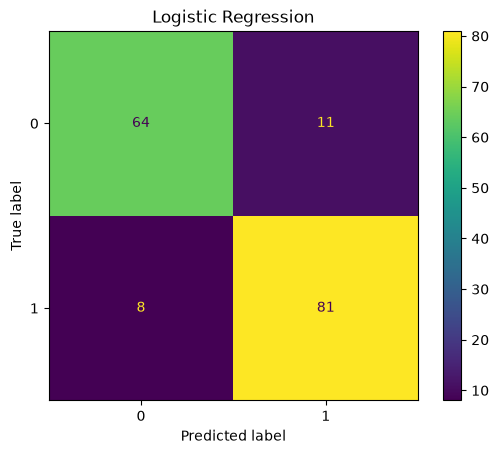

In [7]:
results = []

def evaluate(name, model, show_cm=False):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    
    row = {"Model": name,
           "Accuracy (%)": round(accuracy_score(y_test, pred) * 100, 2),
           "Precision": round(precision_score(y_test, pred), 3),
           "Recall": round(recall_score(y_test, pred), 3),
           "F1": round(f1_score(y_test, pred), 3)}
    
    results.append(row)
    print(row)
    
    if show_cm:
        print("Confusion matrix [[TN FP] [FN TP]]:\n", confusion_matrix(y_test, pred))
        ConfusionMatrixDisplay.from_predictions(y_test, pred)
        plt.title(name); plt.show()
    return model

log_reg = evaluate("Logistic Regression",
                   Pipeline([("prep", make_preprocessor()),
                             ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
                   show_cm=True)

### --> Simple Neural Network

{'Model': 'Neural Net (16 neurons)', 'Accuracy (%)': 87.8, 'Precision': 0.897, 'Recall': 0.876, 'F1': 0.886}
Confusion matrix [[TN FP] [FN TP]]:
 [[66  9]
 [11 78]]


c:\Users\bowes\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


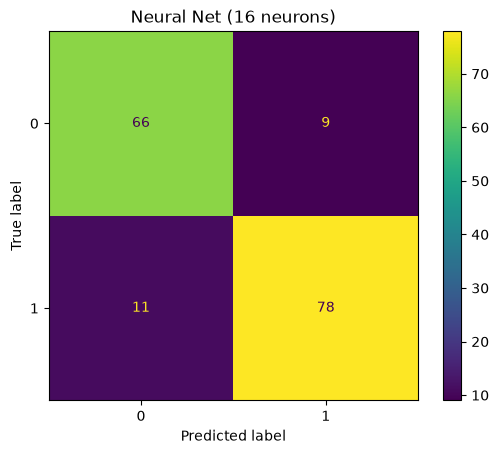

In [8]:
nn_simple = evaluate("Neural Net (16 neurons)",
                    Pipeline([("prep", make_preprocessor()),
                              ("clf", MLPClassifier(hidden_layer_sizes=(16,), max_iter=1000,
                                                    random_state=RANDOM_STATE))]),
                    show_cm=True)

### --> Scaling

**Logistic regression and neural networks learn by gradient descent, so features on very different scales (like Cholesterol in the hundreds versus Oldpeak near 0-3) make some features dominate the updates, which slows or destabilises training. Scaling puts all features on a comparable range so they are treated fairly and the model converges faster and more reliably.**

**Scaling made no difference for logistic regression and slightly hurt the neural network. That is a normal result for a small dataset with few features, where a modern solver can cope with unscaled inputs.**

### --> Larger Neural Network (~100 neurons per layer)

In [9]:
nn_large = evaluate("Neural Net (100, 100)",
                  Pipeline([("prep", make_preprocessor()),
                            ("clf", MLPClassifier(hidden_layer_sizes=(100, 100), max_iter=1000,
                                                  random_state=RANDOM_STATE))]))

{'Model': 'Neural Net (100, 100)', 'Accuracy (%)': 88.41, 'Precision': 0.889, 'Recall': 0.899, 'F1': 0.894}


**The accuracy decreased, and it's likely due to overfitting. The training set is small (a few hundred patients) but a 100x100 network has roughly 11,000+ weights, so it can memorise noise and individual patients in the training data instead of learning general patterns, which hurts performance on unseen data.**

### --> Other Models (SVM, Random Forest, Decision Trees and KNN)

In [10]:
evaluate("SVM (default)", Pipeline([("prep", make_preprocessor()), ("clf", SVC(random_state=RANDOM_STATE))]))
evaluate("Random Forest (default)", Pipeline([("prep", make_preprocessor()), ("clf", RandomForestClassifier(random_state=RANDOM_STATE))]))
evaluate("Decision Tree (default)", Pipeline([("prep", make_preprocessor()), ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))]))
evaluate("KNN (default)", Pipeline([("prep", make_preprocessor()), ("clf", KNeighborsClassifier())]))

{'Model': 'SVM (default)', 'Accuracy (%)': 90.24, 'Precision': 0.892, 'Recall': 0.933, 'F1': 0.912}
{'Model': 'Random Forest (default)', 'Accuracy (%)': 90.24, 'Precision': 0.91, 'Recall': 0.91, 'F1': 0.91}
{'Model': 'Decision Tree (default)', 'Accuracy (%)': 79.27, 'Precision': 0.802, 'Recall': 0.82, 'F1': 0.811}
{'Model': 'KNN (default)', 'Accuracy (%)': 87.8, 'Precision': 0.863, 'Recall': 0.921, 'F1': 0.891}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Age','Sex','ChestPainType',...,'ExerciseAngina','Oldpeak','ST_Slope']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining 

## --> Grid Search with k-fold cross-validation

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search_space = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), {"clf__C": [0.01, 0.1, 1, 10, 100]}),
    
    "SVM": (SVC(random_state=RANDOM_STATE), {"clf__C": [0.1, 1, 10], "clf__kernel": ["linear", "rbf"], "clf__gamma": ["scale", 0.01, 0.1]}),
    
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE),{"clf__n_estimators": [100, 300], "clf__max_depth": [None, 5, 10],
                       "clf__min_samples_leaf": [1, 3]}),
    
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), {"clf__max_depth": [3, 5, 7, None], "clf__min_samples_leaf": [1, 5, 10]}),
    
    "KNN": (KNeighborsClassifier(), {"clf__n_neighbors": [3, 5, 7, 9, 15], "clf__weights": ["uniform", "distance"]}),
    
    "Neural Net": (MLPClassifier(max_iter=1000, random_state=RANDOM_STATE), {"clf__hidden_layer_sizes": [(8,), (16,), (32,), (100, 100)],
                    "clf__alpha": [0.0001, 0.01, 0.1]}),
}

best_models, cv_rows = {}, []

for name, (clf, grid) in search_space.items():
    gs = GridSearchCV(Pipeline([("prep", make_preprocessor()), ("clf", clf)]),
                      grid, cv=cv, scoring="accuracy", n_jobs=-1)
    
    gs.fit(X_train, y_train)
    best_models[name] = gs.best_estimator_
    pred = gs.best_estimator_.predict(X_test)
    
    cv_rows.append({"Model": name, "Best CV accuracy (%)": round(gs.best_score_ * 100, 2),
                    "Test accuracy (%)": round(accuracy_score(y_test, pred) * 100, 2),
                    "Precision": round(precision_score(y_test, pred), 3),
                    "Recall": round(recall_score(y_test, pred), 3),
                    "F1": round(f1_score(y_test, pred), 3),
                    "Best params": gs.best_params_})
    
    results.append({"Model": name + " (tuned)", "Accuracy (%)": round(accuracy_score(y_test, pred) * 100, 2),
                    "Precision": round(precision_score(y_test, pred), 3),
                    "Recall": round(recall_score(y_test, pred), 3),
                    "F1": round(f1_score(y_test, pred), 3)})

cv_table = pd.DataFrame(cv_rows).sort_values("Best CV accuracy (%)", ascending=False)
cv_table

,Model,Best CV accuracy (%),Test accuracy (%),Precision,Recall,F1,Best params
1,SVM,86.40,89.63,0.891,0.921,0.906,"{'clf__C': 1, 'clf__gamma': 0.01, 'clf__kernel..."
0,Logistic Regression,86.09,89.02,0.882,0.921,0.901,{'clf__C': 0.1}
2,Random Forest,85.94,89.63,0.909,0.899,0.904,"{'clf__max_depth': None, 'clf__min_samples_lea..."
4,KNN,85.33,87.20,0.862,0.910,0.885,"{'clf__n_neighbors': 5, 'clf__weights': 'dista..."
5,Neural Net,84.87,87.80,0.888,0.888,0.888,"{'clf__alpha': 0.0001, 'clf__hidden_layer_size..."
3,Decision Tree,82.27,85.98,0.851,0.899,0.874,"{'clf__max_depth': 5, 'clf__min_samples_leaf': 1}"


### --> Summary Table of Every Model

In [12]:
pd.DataFrame(results)

,Model,Accuracy (%),Precision,Recall,F1
0,Logistic Regression,88.41,0.880,0.910,0.895
1,Neural Net (16 neurons),87.80,0.897,0.876,0.886
2,"Neural Net (100, 100)",88.41,0.889,0.899,0.894
3,SVM (default),90.24,0.892,0.933,0.912
4,Random Forest (default),90.24,0.910,0.910,0.910
5,Decision Tree (default),79.27,0.802,0.820,0.811
6,KNN (default),87.80,0.863,0.921,0.891
7,Logistic Regression (tuned),89.02,0.882,0.921,0.901
8,SVM (tuned),89.63,0.891,0.921,0.906
9,Random Forest (tuned),89.63,0.909,0.899,0.904


### --> Chosen Model

In [13]:
best_name = cv_table.iloc[0]["Model"]
print("Chosen model:", best_name, "\n", cv_table.iloc[0]["Best params"])

Chosen model: SVM 
 {'clf__C': 1, 'clf__gamma': 0.01, 'clf__kernel': 'rbf'}


### --> Handling Imbalanced Datasets

Imbalanced datasets are handled by choosing better metrics and by adjusting how the data or model treats the minority class. Accuracy can be misleading when one class dominates, so precision, recall, F1 and the confusion matrix should be used instead, with recall especially important in medical settings where a missed patient is costly. Stratified splitting and stratified k-fold keep the class ratio consistent across splits. The training data can be resampled by oversampling the minority class (for example with SMOTE) or undersampling the majority class, but only inside the training folds to avoid leakage. Alternatively, class weights (class_weight="balanced") penalise minority-class errors more, and the decision threshold can be lowered to favour recall. In this dataset the split is about 54.5% disease and 45.5% healthy, so it is only mildly imbalanced and accuracy remains a reasonable metric.

### --> Kaggle Predictions

In [ ]:
final_model = best_models[best_name]
final_model.fit(X, y)

X_kaggle = test_df.drop(columns=["PatientId"])
X_kaggle[categorical_cols] = X_kaggle[categorical_cols].astype(str)

submission = pd.DataFrame({"PatientId": test_df["PatientId"], "HeartDisease": final_model.predict(X_kaggle).astype(int)})

submission.to_csv("submission.csv", index=False)
print(submission.shape, submission["HeartDisease"].value_counts().to_dict())
submission.head()